# Does Central Bank Communication Improve Stock-Market Return Forecasts?
**Evidence from Egyptian Banks and Real Estate Sectors**

Ahmed Yasser · 13007130

**Horizon:** first actual trading session strictly after each announcement.

## 1. Research design

- **Inputs:** prior sector/EGX30 returns, observed policy action; legacy indicator in full history.
- **Text:** past-trained Word2Vec → four training-only PCs, not sentiment scores.
- **Models:** Ridge, Elastic Net, RBF SVR and Random Forest; paired numerical/text variants.
- **Evaluation:** expanding chronological training; fixed settings, no tuning.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import hashlib
import io
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

ARCHIVE_NAME = "Code_and_Processed_Data.zip"
EXPECTED_ARCHIVE_SHA256 = "ceacf276144dfd4304ee86c9ab3439fb4686d38d6580a29bb43bd4692c20e157"
DATA = "04_data/processed/first_session_only_2026-10-28"
RESULTS = "06_results/first_session_only_2026-10-28/run_001"
PROTOCOL = "03_methodology/first_session_only_2026-10-28/protocol.json"

# Work from the handover folder or anywhere inside the thesis workspace.
search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
candidates = []
for base in search_roots:
    candidates.extend([
        base / ARCHIVE_NAME,
        base / "10_submissions/2026-11-01_final_local_review" / ARCHIVE_NAME,
    ])
archive_path = next((p for p in candidates if p.is_file()), None)
if archive_path is None:
    raise FileNotFoundError("Place Code_and_Processed_Data.zip beside this notebook.")
archive_sha256 = hashlib.sha256(archive_path.read_bytes()).hexdigest()
assert archive_sha256 == EXPECTED_ARCHIVE_SHA256, "Supporting archive version differs."

source_hashes = {}
def read_member(member):
    with ZipFile(archive_path) as archive:
        content = archive.read(member)
    source_hashes[member] = hashlib.sha256(content).hexdigest()
    return content

def read_csv(member):
    return pd.read_csv(io.BytesIO(read_member(member)))

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 12, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#525252", "axes.labelcolor": "#262626",
    "text.color": "#262626", "xtick.color": "#404040", "ytick.color": "#404040",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "figure.dpi": 110,
})
CASES = {
    "expanded_legacy_live": "Full history",
    "modern_live_only": "Modern-live (2020 onwards)",
}
SECTORS = {"banks": "Banks", "real_estate": "Real Estate"}
FAMILIES = {
    "ridge": "Ridge", "elastic_net": "Elastic Net",
    "rbf_svr": "RBF SVR", "random_forest": "Random Forest",
}
GROUPS = [(case, sector) for case in CASES for sector in SECTORS]

## 2. Dataset and evaluation samples

**Sources:** original CBE statements/actions; Refinitiv .EGBANK, .EGREAL and .EGX30 closes.

In [2]:
protocol = json.loads(read_member(PROTOCOL))
inventory = read_csv(f"{DATA}/original_text_inventory.csv")
cohort = read_csv(f"{DATA}/common_event_cohort.csv")
panel = read_csv(f"{DATA}/event_sector_modeling.csv")
predictions = read_csv(f"{RESULTS}/predictions.csv")
metrics = read_csv(f"{RESULTS}/metrics.csv")
paired = read_csv(f"{RESULTS}/paired_text_differences.csv")
assert protocol["horizons"] == ["first_session"]
for frame in [predictions, metrics, paired]:
    assert set(frame["horizon"]) == {"first_session"}, "Unexpected forecast horizon."
assert len(cohort) == cohort["doc_id"].nunique() == 155
eligible_panel = panel.loc[panel["in_common_event_cohort"]].copy()
assert len(eligible_panel) == 310
assert (len(predictions), len(metrics), len(paired)) == (3100, 40, 16)
display(pd.DataFrame({
    "Dataset component": [
        "Original document inventory", "Common eligible announcements",
        "Banks and Real Estate outcomes", "Saved first-session forecasts",
    ],
    "Records": [len(inventory), len(cohort), len(eligible_panel), len(predictions)],
}).style.hide(axis="index"))

sample_rows = []
for case, label in CASES.items():
    case_cohort = (
        cohort if case == "expanded_legacy_live"
        else cohort.loc[cohort["sector_definition"].eq("modern_live_from_2020_01_02")]
    )
    scored = predictions.loc[predictions["case"].eq(case)]
    sample_rows.append({
        "Sample": label, "Eligible events": len(case_cohort),
        "Initial training": protocol["initial_training_events"][case],
        "Evaluation events": scored["doc_id"].nunique(),
        "First eligible": case_cohort["event_date"].min(),
        "Last eligible": case_cohort["event_date"].max(),
    })
display(pd.DataFrame(sample_rows).style.hide(axis="index"))

Dataset component,Records
Original document inventory,176
Common eligible announcements,155
Banks and Real Estate outcomes,310
Saved first-session forecasts,3100


Sample,Eligible events,Initial training,Evaluation events,First eligible,Last eligible
Full history,155,36,119,2007-02-01,2026-09-24
Modern-live (2020 onwards),56,20,36,2020-01-16,2026-09-24


**Units:** returns (%), errors (pp), policy action (bps).
Session dates account for closures; sector rows and overlapping samples are not independent events.

## 3. Data description and exploratory analysis

Common calendar interval: 3 January 2007 to 18 October 2026. Available closes/returns only; no imputation. Event statistics use all 155 common announcements. SD uses n−1; quartiles use linear interpolation. Policy-level provenance is review-only. No model fitting.

In [3]:
import importlib.util
eda_path = archive_path.parent / "Chapter4" / "chapter4_analysis.py"
spec = importlib.util.spec_from_file_location("chapter4_analysis", eda_path)
eda = importlib.util.module_from_spec(spec)
spec.loader.exec_module(eda)
daily_prices = read_csv(f"{DATA}/daily_prices.csv")
rate_levels = pd.read_csv(eda_path.parent / "policy_rate_provenance_v2.csv")
eda_data = eda.prepare(inventory, panel, daily_prices, rate_levels)
eda_tables = eda.tables(eda_data)
eda_rc_before = plt.rcParams.copy()
eda.style()
display(eda_tables["table_4_1"].style.hide(axis="index"))

Population or exclusion,Count,Meaning
All original documents,176,Document inventory
Policy-statement candidates,174,173 English and 1 Arabic only
English policy candidates,173,Language-eligible inventory
Arabic-only policy candidate,1,Excluded from English model
Administrative notices,2,Excluded from policy model
English candidates before sector history,16,Excluded before January 2007
English candidates in shared 2011 reopening window,2,Excluded by event-window rules
Common eligible English policy events,155,99 legacy and 56 modern-live
First-session sector outcomes,310,155 Banks and 155 Real Estate


### Policy decisions and deposit-rate levels

Annual action percentages use eligible events in each year. Level markers distinguish source-stated after-levels from inferred before-levels; 5 November 2009 is conditional continuity. Corrections do not alter model inputs.

In [4]:
display(eda_tables["table_4_2"].round(4).style.hide(axis="index"))
display(eda_tables["table_4_3"].round(2).style.hide(axis="index"))

Sample,n,mean,median,sd,min,q1,q3,max
Common cohort,155,4.677400,0.000000,84.745000,-300.000000,0.000000,0.000000,600.000000
Legacy,99,0.505100,0.000000,50.882500,-150.000000,0.000000,0.000000,200.000000
Modern-live,56,12.053600,0.000000,124.132500,-300.000000,0.000000,0.000000,600.000000


Year,Documents,Policy_candidates,English_policy_candidates,Eligible,hike_n,hike_pct,cut_n,cut_pct,hold_n,hold_pct
2005,7,7,7,0,0,nan,0,nan,0,nan
2006,10,9,9,0,0,nan,0,nan,0,nan
2007,8,8,8,8,0,0.000000,0,0.000000,8,100.000000
2008,8,8,8,8,6,75.000000,0,0.000000,2,25.000000
2009,8,8,8,8,0,0.000000,6,75.000000,2,25.000000
2010,8,8,8,8,0,0.000000,0,0.000000,8,100.000000
2011,7,7,7,5,1,20.000000,0,0.000000,4,80.000000
2012,8,8,7,7,0,0.000000,0,0.000000,7,100.000000
2013,8,8,8,8,1,12.500000,3,37.500000,4,50.000000
2014,8,8,8,8,1,12.500000,0,0.000000,7,87.500000


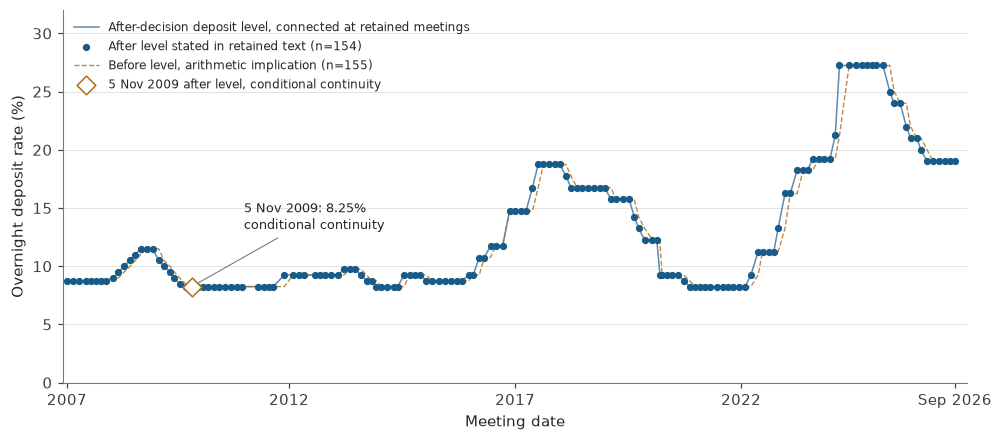

In [5]:
fig = eda.policy_plot(eda_data)
display(fig)
plt.close(fig)

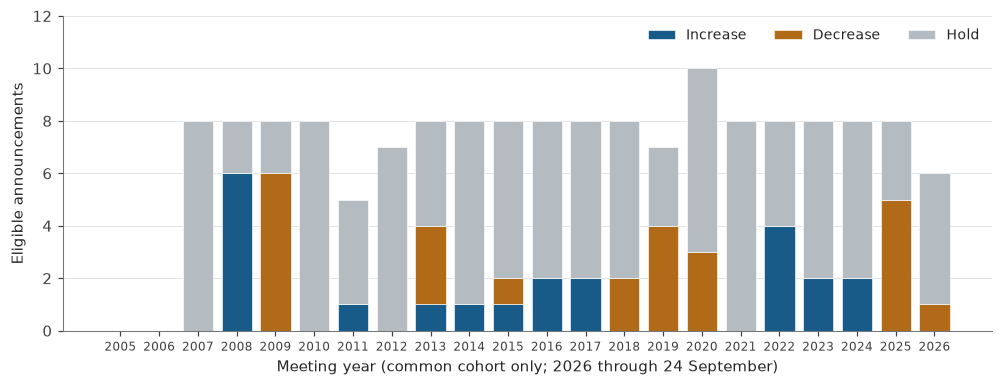

In [6]:
fig = eda.annual_plot(eda_data)
display(fig)
plt.close(fig)

### Daily market data

Price levels are index points. Returns are percent per session. Separate 100-point bases mark legacy and modern-live definitions; rebasing does not establish index equivalence.

In [7]:
display(eda_tables["table_4_4"].round(4).style.hide(axis="index"))
display(eda_tables["table_4_5"].round(4).style.hide(axis="index"))

Index,n,mean,median,sd,min,q1,q3,max
EGBANK,4787,2689.401800,1776.140000,1957.342400,637.210000,1180.330000,3554.035000,7774.860000
EGREAL,4787,1584.925800,1228.350000,1087.375800,424.300000,838.860000,1801.220000,6752.860000
EGX30,4788,13571.553000,10202.980000,10877.962100,3389.310000,6782.495000,14583.590000,56676.160000


Index,n,mean,median,sd,min,q1,q3,max
EGBANK,4784,0.087700,0.082300,1.559700,-20.678900,-0.646100,0.857400,13.332000
EGREAL,4784,0.068600,0.090400,2.074300,-21.638800,-0.965900,1.171600,12.756200
EGX30,4787,0.052900,0.096800,1.529100,-16.466000,-0.683500,0.850700,7.588500


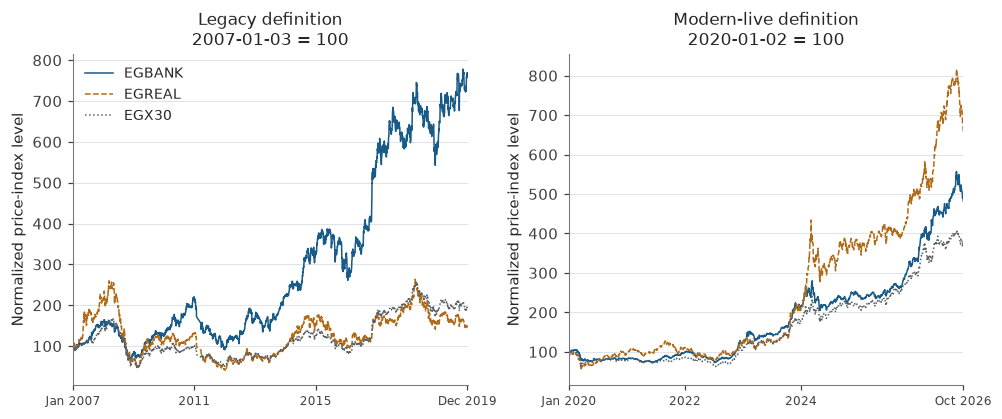

In [8]:
fig = eda.index_plot(eda_data)
display(fig)
plt.close(fig)

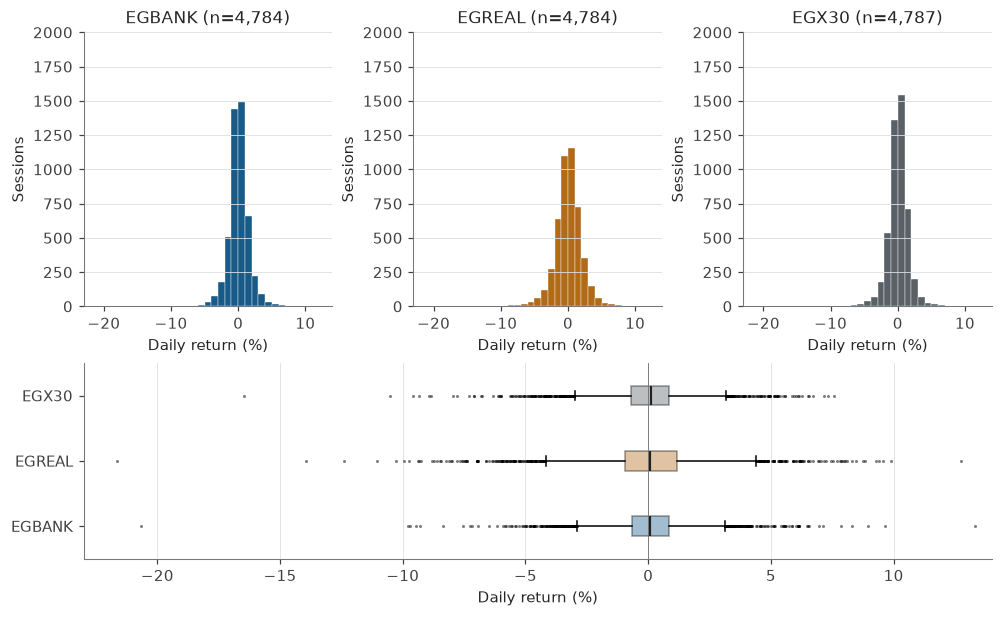

In [9]:
fig = eda.daily_plot(eda_data)
display(fig)
plt.close(fig)

### First-session outcomes and sample coverage

These describe all eligible event outcomes, including initial training events. The modern-live sample overlaps the larger history. Boxplot points beyond 1.5 interquartile ranges remain visible.

In [10]:
display(eda_tables["table_4_6"].round(4).style.hide(axis="index"))
display(eda_tables["table_4_7"].style.hide(axis="index"))

Sector,n,mean,median,sd,min,q1,q3,max,Positive,Negative,Zero
Banks,155,0.135800,0.018500,1.666900,-5.931300,-0.650100,0.793600,7.132600,78,76,1
Real Estate,155,-0.014400,0.000000,2.165900,-7.676800,-1.247500,1.177300,7.852100,77,77,1


Sample,Announcement dates,Events,Legacy,Modern,Sector outcomes,Initial training events,Evaluation events,Evaluation sector outcomes,Evaluation meeting dates
Full history,1 Feb 2007 to 24 Sep 2026,155,99,56,310,36,119,238,24 Nov 2011 to 24 Sep 2026
Modern-live,16 Jan 2020 to 24 Sep 2026,56,0,56,112,20,36,72,19 May 2022 to 24 Sep 2026


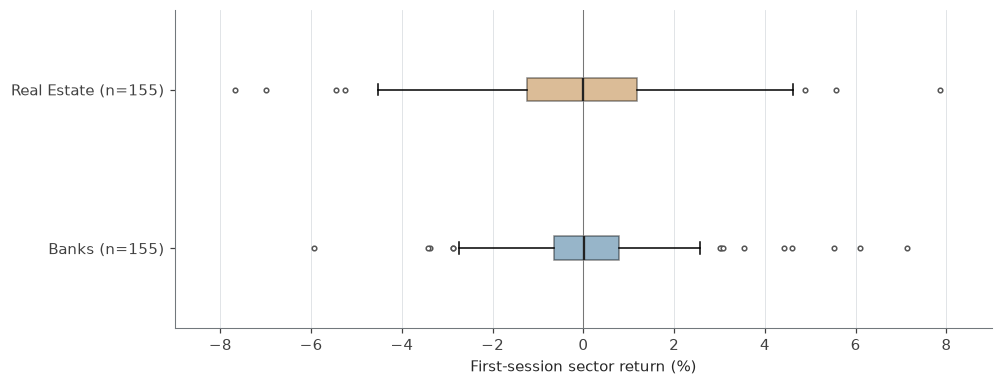

In [11]:
fig = eda.event_plot(eda_data)
display(fig)
plt.close(fig)

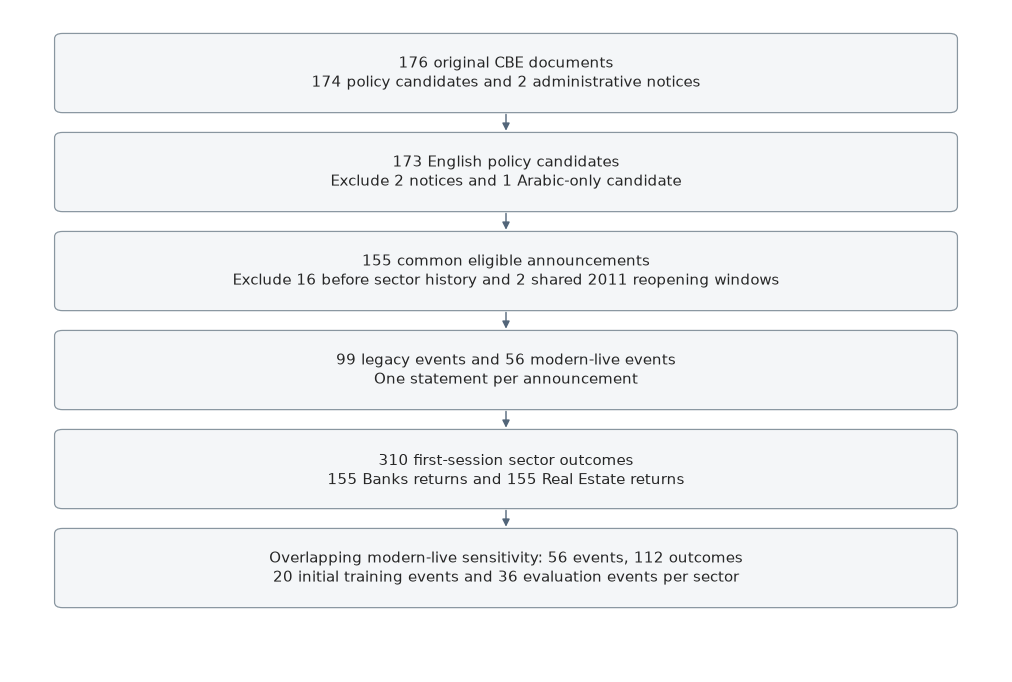

In [12]:
fig = eda.sample_plot(eda_data)
display(fig)
plt.close(fig)

Holds account for 108/155 decisions. Real Estate shows greater descriptive dispersion than Banks in both daily and event returns. These summaries do not identify a causal communication effect.

In [13]:
plt.rcParams.update(eda_rc_before)

## 4. Does adding statement text improve forecasts?

ΔMAE = text − numerical (pp); **negative favours text**.
Saved 95% descriptive circular-block intervals: 2,000 replications,
five-announcement blocks; unadjusted for multiple comparisons.

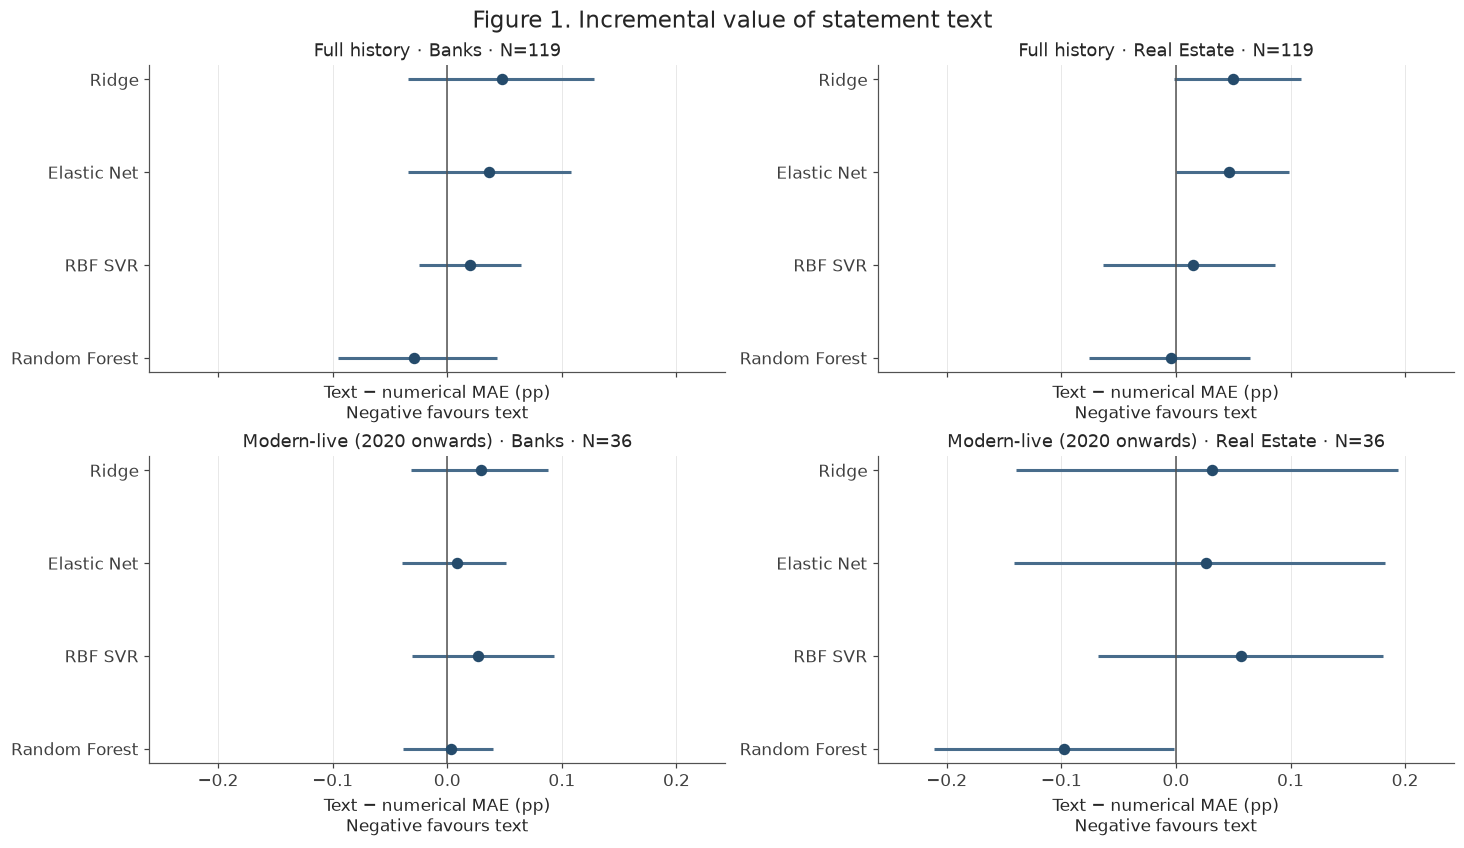

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13.2, 7.6), sharex=True, layout="constrained")
lower = min(0.0, paired["MAE_difference_pp_low"].min())
upper = max(0.0, paired["MAE_difference_pp_high"].max())
padding = (upper - lower) * 0.12
for ax, (case, sector) in zip(axes.flat, GROUPS):
    values = paired.loc[
        paired["case"].eq(case) & paired["sector"].eq(sector)
    ].set_index("family").loc[list(FAMILIES)]
    positions = np.arange(len(values))
    ax.hlines(
        positions, values["MAE_difference_pp_low"],
        values["MAE_difference_pp_high"], color="#486c8b", linewidth=2,
    )
    ax.scatter(values["MAE_difference_pp"], positions, color="#254b6b", s=42, zorder=3)
    ax.axvline(0, color="#525252", linewidth=1)
    ax.set_yticks(positions, list(FAMILIES.values()))
    ax.invert_yaxis()
    ax.set_xlim(lower - padding, upper + padding)
    ax.set_title(f"{CASES[case]} · {SECTORS[sector]} · N={int(values['test_events'].iloc[0])}")
    ax.set_xlabel("Text − numerical MAE (pp)\nNegative favours text")
    ax.grid(axis="x", color="#e6e6e6", linewidth=0.6)
fig.suptitle("Figure 1. Incremental value of statement text", fontsize=15)
plt.show()

In [15]:
text_mae_improvements = int(paired["MAE_difference_pp"].lt(0).sum())
intervals_containing_zero = int((
    paired["MAE_difference_pp_low"].le(0)
    & paired["MAE_difference_pp_high"].ge(0)
).sum())
assert (text_mae_improvements, intervals_containing_zero) == (3, 15)
display(Markdown(
    f"**Lower text MAE:** {text_mae_improvements}/{len(paired)} pairs. "
    f"**Descriptive intervals containing zero:** {intervals_containing_zero}/{len(paired)}."
))

**Lower text MAE:** 3/16 pairs. **Descriptive intervals containing zero:** 15/16.

## 5. Absolute forecast performance

MAE (pp); lower is better. References: historical mean and zero return.

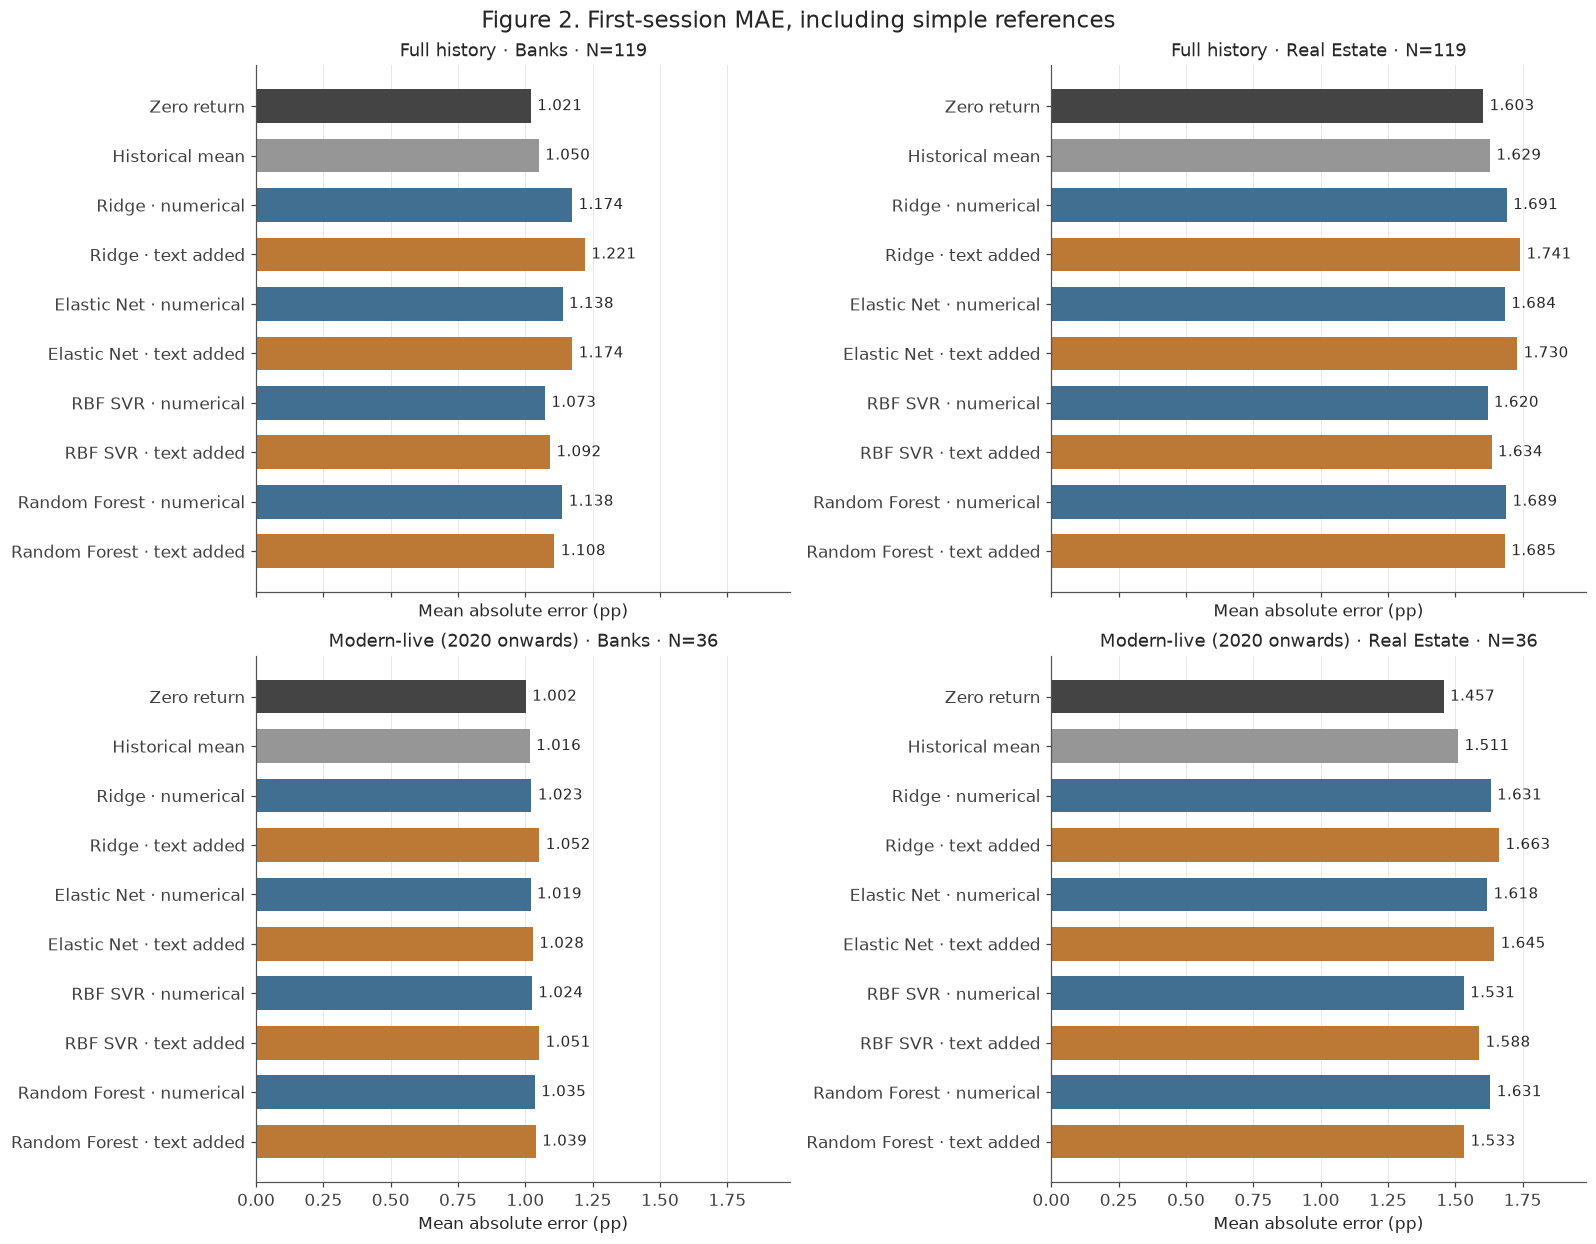

In [16]:
def forecast_label(family, variant):
    if family == "zero_return":
        return "Zero return"
    if family == "historical_mean":
        return "Historical mean"
    suffix = "numerical" if variant == "numerical" else "text added"
    return f"{FAMILIES[family]} · {suffix}"

forecast_order = [("zero_return", "reference"), ("historical_mean", "reference")]
forecast_order += [
    (family, variant) for family in FAMILIES
    for variant in ["numerical", "text_added"]
]
order_lookup = {key: position for position, key in enumerate(forecast_order)}
colours = {
    "zero_return": "#444444", "historical_mean": "#969696",
    "numerical": "#416f91", "text_added": "#bb7935",
}
fig, axes = plt.subplots(2, 2, figsize=(14.4, 11.2), sharex=True, layout="constrained")
maximum = metrics["MAE_pp"].max() * 1.14
for ax, (case, sector) in zip(axes.flat, GROUPS):
    group = metrics.loc[
        metrics["case"].eq(case) & metrics["sector"].eq(sector)
    ].copy()
    group["order"] = [order_lookup[(r.family, r.variant)] for r in group.itertuples()]
    group = group.sort_values("order")
    labels = [forecast_label(r.family, r.variant) for r in group.itertuples()]
    fills = [
        colours[r.family] if r.variant == "reference" else colours[r.variant]
        for r in group.itertuples()
    ]
    ax.barh(labels, group["MAE_pp"], color=fills, height=0.68)
    ax.invert_yaxis()
    ax.set_xlim(0, maximum)
    ax.set_xlabel("Mean absolute error (pp)")
    ax.set_title(f"{CASES[case]} · {SECTORS[sector]} · N={int(group['test_events'].iloc[0])}")
    ax.grid(axis="x", color="#e6e6e6", linewidth=0.6)
    ax.set_axisbelow(True)
    for position, value in enumerate(group["MAE_pp"]):
        ax.text(value + maximum * 0.012, position, f"{value:.3f}", va="center", fontsize=10)
fig.suptitle("Figure 2. First-session MAE, including simple references", fontsize=15)
plt.show()

### Complete score tables

R² uses the expanding training mean. Direction excludes flat actuals;
zero predictions miss nonzero actuals. Balanced direction averages up/down recall.

In [17]:
def show_scores(case, sector, number):
    group = metrics.loc[
        metrics["case"].eq(case) & metrics["sector"].eq(sector)
    ].copy()
    group["order"] = [order_lookup[(r.family, r.variant)] for r in group.itertuples()]
    group = group.sort_values("order")
    table = pd.DataFrame({
        "Forecast": [forecast_label(r.family, r.variant) for r in group.itertuples()],
        "N": group["test_events"].to_numpy(),
        "MAE (pp)": group["MAE_pp"].to_numpy(),
        "RMSE (pp)": group["RMSE_pp"].to_numpy(),
        "R² vs mean": group["R2_OS"].to_numpy(),
        "Direction": group["direction_accuracy"].to_numpy(),
        "Balanced direction": group["balanced_direction_accuracy"].to_numpy(),
    })
    display(Markdown(f"**Table {number}. {CASES[case]} — {SECTORS[sector]}**"))
    display(table.style.hide(axis="index").format({
        "N": "{:.0f}", "MAE (pp)": "{:.4f}", "RMSE (pp)": "{:.4f}",
        "R² vs mean": "{:.4f}", "Direction": "{:.1%}", "Balanced direction": "{:.1%}",
    }).set_properties(**{"text-align": "right"}).set_table_styles([
        {"selector": "th", "props": [
            ("text-align", "left"), ("border-bottom", "1px solid #b9b9b9"),
            ("font-weight", "600"), ("padding", "7px 9px"),
        ]},
        {"selector": "td", "props": [
            ("padding", "6px 9px"), ("border-bottom", "1px solid #ededed"),
        ]},
        {"selector": "td.col0", "props": [("text-align", "left")]},
    ]))

show_scores("expanded_legacy_live", "banks", 1)

**Table 1. Full history — Banks**

Forecast,N,MAE (pp),RMSE (pp),R² vs mean,Direction,Balanced direction
Zero return,119,1.0206,1.5229,0.0093,0.0%,0.0%
Historical mean,119,1.0500,1.5300,0.0000,47.5%,50.0%
Ridge · numerical,119,1.1738,1.6620,-0.1799,47.5%,47.9%
Ridge · text added,119,1.2213,1.7584,-0.3208,52.5%,52.8%
Elastic Net · numerical,119,1.1382,1.6293,-0.1340,47.5%,47.8%
Elastic Net · text added,119,1.1744,1.7111,-0.2507,50.0%,50.2%
RBF SVR · numerical,119,1.0726,1.5919,-0.0825,50.8%,51.2%
RBF SVR · text added,119,1.0920,1.6060,-0.1018,48.3%,48.4%
Random Forest · numerical,119,1.1375,1.5811,-0.0679,43.2%,44.4%
Random Forest · text added,119,1.1083,1.5585,-0.0375,50.0%,51.2%


In [18]:
show_scores("expanded_legacy_live", "real_estate", 2)

**Table 2. Full history — Real Estate**

Forecast,N,MAE (pp),RMSE (pp),R² vs mean,Direction,Balanced direction
Zero return,119,1.6034,2.1406,0.0198,0.0%,0.0%
Historical mean,119,1.6288,2.1621,0.0000,42.9%,42.4%
Ridge · numerical,119,1.6909,2.3741,-0.2057,52.9%,52.5%
Ridge · text added,119,1.7409,2.4365,-0.2699,51.3%,51.1%
Elastic Net · numerical,119,1.6839,2.3579,-0.1893,50.4%,49.9%
Elastic Net · text added,119,1.7299,2.4081,-0.2404,51.3%,51.1%
RBF SVR · numerical,119,1.6195,2.1554,0.0062,47.1%,47.8%
RBF SVR · text added,119,1.6345,2.1755,-0.0124,52.1%,52.7%
Random Forest · numerical,119,1.6886,2.2414,-0.0747,52.9%,52.8%
Random Forest · text added,119,1.6845,2.2275,-0.0614,46.2%,46.4%


In [19]:
show_scores("modern_live_only", "banks", 3)

**Table 3. Modern-live (2020 onwards) — Banks**

Forecast,N,MAE (pp),RMSE (pp),R² vs mean,Direction,Balanced direction
Zero return,36,1.0016,1.4280,0.0173,0.0%,0.0%
Historical mean,36,1.0164,1.4405,0.0000,36.1%,40.0%
Ridge · numerical,36,1.0228,1.5118,-0.1014,52.8%,50.0%
Ridge · text added,36,1.0521,1.5285,-0.1258,55.6%,53.7%
Elastic Net · numerical,36,1.0193,1.4911,-0.0714,52.8%,50.0%
Elastic Net · text added,36,1.0280,1.4984,-0.0819,52.8%,50.6%
RBF SVR · numerical,36,1.0245,1.4963,-0.0789,58.3%,56.2%
RBF SVR · text added,36,1.0515,1.4528,-0.0171,50.0%,49.4%
Random Forest · numerical,36,1.0351,1.4308,0.0135,55.6%,55.6%
Random Forest · text added,36,1.0387,1.4380,0.0036,52.8%,51.9%


In [20]:
show_scores("modern_live_only", "real_estate", 4)

**Table 4. Modern-live (2020 onwards) — Real Estate**

Forecast,N,MAE (pp),RMSE (pp),R² vs mean,Direction,Balanced direction
Zero return,36,1.4568,1.7755,0.0667,0.0%,0.0%
Historical mean,36,1.5106,1.8379,0.0000,47.2%,50.0%
Ridge · numerical,36,1.6312,2.2584,-0.5100,52.8%,54.3%
Ridge · text added,36,1.6626,2.1873,-0.4164,50.0%,50.5%
Elastic Net · numerical,36,1.6182,2.2439,-0.4906,50.0%,51.4%
Elastic Net · text added,36,1.6447,2.1858,-0.4144,50.0%,50.5%
RBF SVR · numerical,36,1.5315,1.9148,-0.0854,47.2%,47.2%
RBF SVR · text added,36,1.5885,1.9303,-0.1031,44.4%,44.6%
Random Forest · numerical,36,1.6305,1.9876,-0.1696,38.9%,40.2%
Random Forest · text added,36,1.5329,1.9085,-0.0784,50.0%,51.1%


### One announcement, traced from dates to error

Latest evaluated event; modern-live Banks; Ridge and references.

In [21]:
example = predictions.loc[
    predictions["case"].eq("modern_live_only") & predictions["sector"].eq("banks")
]
event_date = example["event_date"].max()
example = example.loc[example["event_date"].eq(event_date)]
dates = example.iloc[0]
display(Markdown(
    f"**Announcement:** {event_date} · "
    f"**Preceding close:** {dates['preceding_session_date']} · "
    f"**First actual trading session:** {dates['first_session_date']}"
))
selected = example.loc[example["family"].isin(["zero_return", "historical_mean", "ridge"])].copy()
selected["order"] = [order_lookup[(r.family, r.variant)] for r in selected.itertuples()]
selected = selected.sort_values("order")
illustration = pd.DataFrame({
    "Forecast": [forecast_label(r.family, r.variant) for r in selected.itertuples()],
    "Actual return (%)": selected["actual_pp"].to_numpy(),
    "Forecast return (%)": selected["prediction_pp"].to_numpy(),
    "Absolute error (pp)": np.abs(selected["prediction_pp"] - selected["actual_pp"]).to_numpy(),
})
display(illustration.style.hide(axis="index").format({
    "Actual return (%)": "{:.4f}", "Forecast return (%)": "{:.4f}",
    "Absolute error (pp)": "{:.4f}",
}))

**Announcement:** 2026-09-24 · **Preceding close:** 2026-09-24 · **First actual trading session:** 2026-09-27

Forecast,Actual return (%),Forecast return (%),Absolute error (pp)
Zero return,-0.4340,0.0000,0.4340
Historical mean,-0.4340,0.1353,0.5693
Ridge · numerical,-0.4340,-0.1165,0.3175
Ridge · text added,-0.4340,0.1189,0.5528


## 6. Conclusion

No consistent text gain under these specifications. Zero return outperforms
all learned variants on MAE and RMSE.

**Limits:** retrospective; unverified release clocks/vintages; changing index
definitions; overlapping samples; previously inspected history. Observed
actions are not policy surprises. No causal or profitability claim.

## Appendix A. Computational checks

Read-only reconciliation; no model fitting or interval regeneration.

In [22]:
group_keys = ["case", "sector", "family", "variant"]
prediction_key = group_keys + ["doc_id"]
assert not predictions.duplicated(prediction_key).any()
assert not metrics.duplicated(group_keys).any()
assert (predictions["last_training_label_end"] < predictions["event_date"]).all()
assert (predictions["first_session_date"] > predictions["event_date"]).all()
assert predictions["target_label_end"].eq(predictions["first_session_date"]).all()

matched = predictions.merge(
    eligible_panel[[
        "doc_id", "sector", "first_session_date", "first_session_return_pct",
        "preceding_session_sector_close", "first_session_sector_close",
    ]],
    on=["doc_id", "sector"], how="left", validate="many_to_one",
    suffixes=("", "_source"), indicator=True,
)
assert matched["_merge"].eq("both").all()
assert matched["first_session_date"].eq(matched["first_session_date_source"]).all()
np.testing.assert_allclose(
    matched["actual_pp"], matched["first_session_return_pct"], rtol=1e-10, atol=2e-10,
)
np.testing.assert_allclose(
    matched["actual_pp"],
    100 * (matched["first_session_sector_close"] / matched["preceding_session_sector_close"] - 1),
    rtol=1e-10, atol=2e-10,
)

saved_scores = metrics.set_index(group_keys)
checked_fields = [
    "test_events", "MAE_pp", "RMSE_pp", "R2_OS",
    "direction_accuracy", "balanced_direction_accuracy",
]
checked_groups = 0
for key, group in predictions.groupby(group_keys, sort=True):
    actual = group["actual_pp"].to_numpy(float)
    forecast = group["prediction_pp"].to_numpy(float)
    baseline = group["historical_mean_pp"].to_numpy(float)
    error = forecast - actual
    nonzero = actual != 0
    up, down = actual > 0, actual < 0
    assert nonzero.any() and up.any() and down.any()
    denominator = np.sum((baseline - actual) ** 2)
    assert denominator > 0
    computed = {
        "test_events": len(group),
        "MAE_pp": np.abs(error).mean(),
        "RMSE_pp": np.sqrt(np.mean(error ** 2)),
        "R2_OS": 1 - np.sum(error ** 2) / denominator,
        "direction_accuracy": np.mean(np.sign(actual[nonzero]) == np.sign(forecast[nonzero])),
        "balanced_direction_accuracy": 0.5 * (
            np.mean(forecast[up] > 0) + np.mean(forecast[down] < 0)
        ),
    }
    for field in checked_fields:
        np.testing.assert_allclose(computed[field], saved_scores.loc[key, field], rtol=1e-10, atol=2e-10)
    checked_groups += 1

for row in paired.itertuples():
    group = predictions.loc[
        predictions["case"].eq(row.case) & predictions["sector"].eq(row.sector)
        & predictions["family"].eq(row.family)
    ]
    numerical = group.loc[group["variant"].eq("numerical")].set_index("doc_id").sort_index()
    text = group.loc[group["variant"].eq("text_added")].set_index("doc_id").sort_index()
    pd.testing.assert_index_equal(numerical.index, text.index)
    np.testing.assert_allclose(numerical["actual_pp"], text["actual_pp"], rtol=0, atol=0)
    assert numerical["training_cohort_sha256"].eq(text["training_cohort_sha256"]).all()
    point = np.mean(
        np.abs(text["prediction_pp"] - text["actual_pp"])
        - np.abs(numerical["prediction_pp"] - numerical["actual_pp"])
    )
    np.testing.assert_allclose(point, row.MAE_difference_pp, rtol=1e-10, atol=2e-10)

learned_variants_behind_zero = 0
for (case, sector), group in metrics.groupby(["case", "sector"]):
    zero = group.loc[group["family"].eq("zero_return")].iloc[0]
    learned = group.loc[group["variant"].isin(["numerical", "text_added"])]
    assert (learned["MAE_pp"] > zero["MAE_pp"]).all()
    assert (learned["RMSE_pp"] > zero["RMSE_pp"]).all()
    learned_variants_behind_zero += len(learned)
assert learned_variants_behind_zero == 32

validation_summary = {
    "Forecast rows matched to source outcomes": len(predictions),
    "Score groups reconciled": checked_groups,
    "Score values reconciled": checked_groups * len(checked_fields),
    "Paired MAE point differences reconciled": len(paired),
    "Active forecast horizons": ", ".join(protocol["horizons"]),
    "New model fits": 0,
    "Bootstrap recalculations": 0,
}
display(pd.DataFrame(
    validation_summary.items(), columns=["Check", "Result"]
).style.hide(axis="index"))

Check,Result
Forecast rows matched to source outcomes,3100
Score groups reconciled,40
Score values reconciled,240
Paired MAE point differences reconciled,16
Active forecast horizons,first_session
New model fits,0
Bootstrap recalculations,0


## Appendix B. Settings

Word2Vec: 100 dimensions, window 5, minimum count 2, 30 epochs, seed 42,
one worker. PCA: four components.

In [23]:
settings_table = pd.DataFrame([
    {"Model": FAMILIES[family], "Fixed settings": json.dumps(settings, sort_keys=True)}
    for family, settings in protocol["model_settings"].items()
])
display(settings_table.style.hide(axis="index").set_properties(**{
    "text-align": "left", "white-space": "normal", "overflow-wrap": "anywhere",
}))

Model,Fixed settings
Elastic Net,"{""alpha"": 0.05, ""fit_intercept"": true, ""l1_ratio"": 0.5, ""max_iter"": 20000, ""selection"": ""cyclic"", ""tol"": 1e-07}"
Random Forest,"{""bootstrap"": true, ""criterion"": ""squared_error"", ""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 8, ""n_estimators"": 128, ""n_jobs"": 1, ""random_state"": 42}"
RBF SVR,"{""C"": 1.0, ""cache_size"": 128, ""epsilon"": 0.1, ""gamma"": ""scale"", ""kernel"": ""rbf"", ""max_iter"": -1, ""tol"": 0.001}"
Ridge,"{""alpha"": 1.0, ""fit_intercept"": true, ""solver"": ""svd""}"
